# Simulate NG15-like data and recover injected GWB

We'll load the NANOGrav 15 year dataset, inject our own red noise and gravitational wave
background, and perform parameter estimation with Prometheus.

In [ ]:
import numpy as np
import pickle
import json
import matplotlib.pyplot as plt
import corner

import jax.random as jr
import numpyro

from enterprise_extensions.load_feathers import load_feathers_from_folder

import pta_sims
from prometheus import data
from prometheus.spectral_models import IndependentSpectralModel, CommonSpectralModel
from prometheus import spectra
from prometheus.pta_model import PTAModel

/home/aidengundersen/anaconda3/envs/pta_sims/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
libstempo not installed. PINT or libstempo are required to use par and tim files.
PINT not installed. PINT or libstempo are required to use par and tim files.


## Load data

In [2]:
# load feather pulsar objects
psrs = load_feathers_from_folder('../data/NG15/feathers')

# load white noise dictionary
with open('../data/NG15/15yr_wn_dict.json', 'r') as fp:
    wn_dict = json.load(fp)

# optional: load dictionary of pulsar distances
# used in CW analysis
with open('../data/NG15/pulsar_distances_15yr.pkl', 'rb') as fp:
    psr_dists_dict = pickle.load(fp)

FeatherPulsar.read_feather: cannot find fitpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J1312+0051.feather.
FeatherPulsar.read_feather: cannot find setpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J1312+0051.feather.
FeatherPulsar.read_feather: cannot find _pdist in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J1312+0051.feather.
FeatherPulsar.read_feather: cannot find fitpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0613-0200.feather.
FeatherPulsar.read_feather: cannot find setpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0613-0200.feather.
FeatherPulsar.read_feather: cannot find _pdist in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0613-0200.feather.
FeatherPulsar.read_feather: cannot find fitpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0610-2100.feather.
FeatherPulsar.read_feather: cannot find setpars in feather file ../data/NG15/feathers

In [3]:
# now we can construct the prometheus.data.Data object
dataset = data.Data(name='NG15',
                    psrs=psrs,
                    wn_dict=wn_dict,
                    nfreqs=30,
                    psr_dists_dict=psr_dists_dict)

building pulsar models: 100%|██████████| 67/67 [00:23<00:00,  2.86it/s, running J0437-4715]


In [ ]:
# save the data object for future analyses
dataset.save_data(filepath='../data/NG15/data.pkl')

# # or load a previously constructed data object
# with open('../data/NG15/data.pkl', 'rb') as fp:
#     dataset = pickle.load(fp)

## Inject GWB & IRN

In [ ]:
# simulation model: a power law per pulsar, plus a Hellings-Downs correlated background
model = pta_sims.build_standard_model(dataset, correlations='HD')

# injected parameters
rng = np.random.default_rng(42)
params = {'red_noise': pta_sims.power_law_params(
                           rng.normal(-15.5, 0.3, dataset.npsrs),
                           rng.normal(2.5, 0.4, dataset.npsrs),
                           npsrs=dataset.npsrs),
          'gwb':       pta_sims.power_law_params(-14.6, 13 / 3)}

# simulate data
simulated_dataset = pta_sims.simulate(model, params, seed=42)
print(simulated_dataset.summary())

Simulated dataset "NG15_sim"
  pulsars 67, stochastic components 60, deterministic components 120
  white noise included: True
  joint Gram rank 18-63 of 180 (truncation rtol 1e-12)
  largest negative-eigenvalue fraction 8.02e-14  (float64 rounding floor ~1e-15; >1e-13 means the stored Gram matrix is itself no longer numerically PSD)
  trace discarded by truncation 1.10e-12
  float32 downcast into Data:
    FNrs     max rel err 5.83e-08, 0 non-finite, 0 underflowed to zero (range 1.09e-08 .. 4.19e+00)
    FNFs     max rel err 5.96e-08, 0 non-finite, 0 underflowed to zero (range 3.04e-14 .. 2.96e-02)
    TDNrs    max rel err 5.93e-08, 0 non-finite, 0 underflowed to zero (range 5.47e-10 .. 5.18e+00)
    TNTDs    max rel err 5.96e-08, 0 non-finite, 0 underflowed to zero (range 5.14e-17 .. 2.90e-02)
    TDNTDs   max rel err 5.96e-08, 0 non-finite, 0 underflowed to zero (range 2.59e-18 .. 2.96e-02)


## Recovery models

In [6]:
# pulsar intrinsic noise model
psr_model = IndependentSpectralModel(name='psr_params',
                                     get_phi_diag_func=spectra.power_law,
                                     parameter_bounds=[[-20., -10.],
                                                       [0., 7.]],
                                     data=simulated_dataset.data)

# background model
gwb_model = CommonSpectralModel(name='gwb_params',
                                get_phi_diag_func=spectra.power_law,
                                parameter_bounds=[[-20., -10.],
                                                    [0., 7.]],
                                correlation_matrix='HD',
                                data=simulated_dataset.data)

# joint PTA model
pta_model = PTAModel(psr_model=psr_model, gwb_model=gwb_model)

In [7]:
nuts_kernel = numpyro.infer.NUTS(model=pta_model.sampling_model)
mcmc = numpyro.infer.MCMC(sampler=nuts_kernel,
                          num_warmup=500,
                          num_samples=1000)
mcmc.run(jr.key(1234))
samples = mcmc.get_samples()

sample: 100%|██████████| 1500/1500 [04:35<00:00,  5.44it/s, 127 steps of size 3.93e-02. acc. prob=0.90]


## Plot recovery

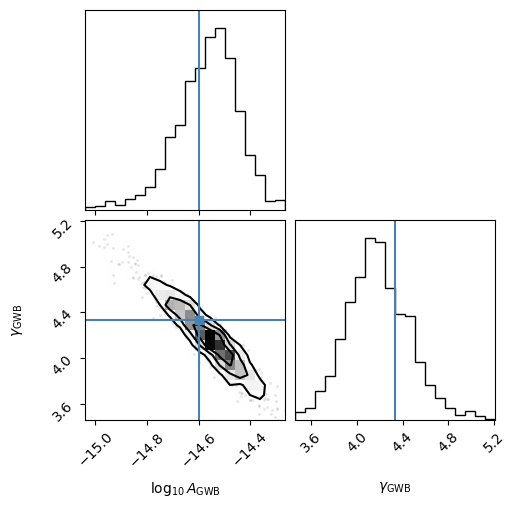

In [8]:
# GWB recovery
fig = corner.corner(data=np.array(samples['gwb_params']),
                    labels=[r'$\log_{10}A_\text{GWB}$', r'$\gamma_\text{GWB}$'],
                    truths=params['gwb'])

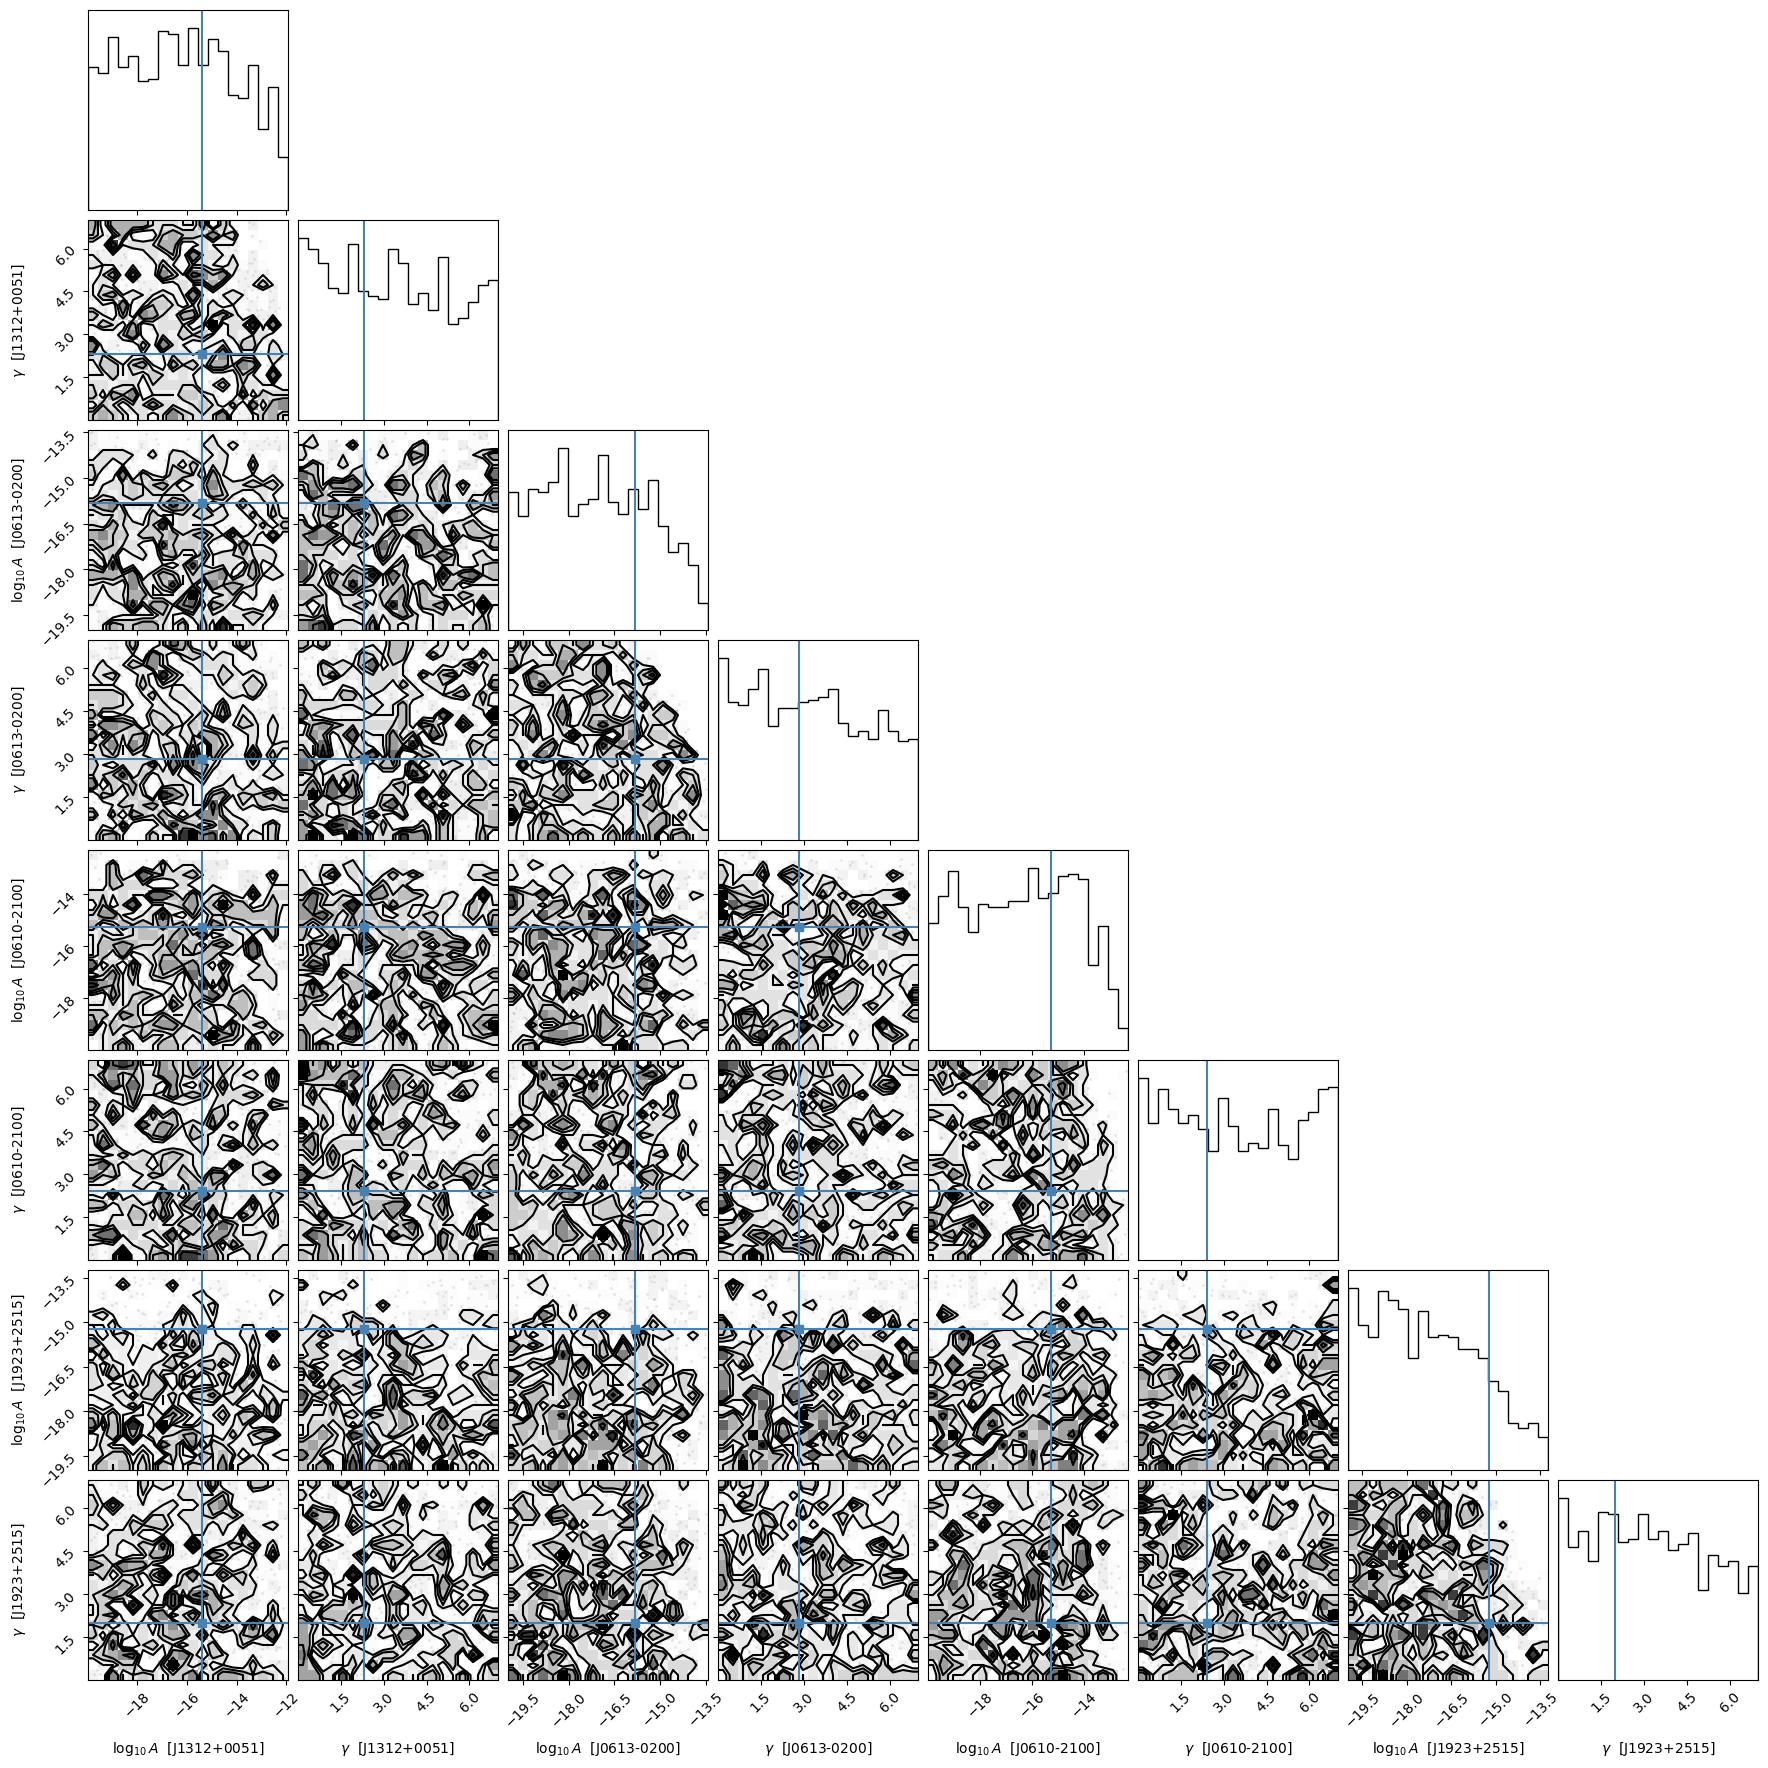

In [9]:
# pulsar noise recovery, for the first few pulsars
psr_ndx = np.r_[0:4]
psr_names = np.array(dataset.psr_names)[psr_ndx]
psr_noise_labels = np.array([[r'$\log_{10}A$' + f'  [{name}]', rf'$\gamma$  [{name}]']
                             for name in psr_names]).flatten()

fig = corner.corner(
    data=np.array(samples['psr_params'][:, psr_ndx, :]).reshape(-1, 2 * len(psr_ndx)),
    labels=psr_noise_labels,
    truths=params['red_noise'][psr_ndx].flatten())